# Фаза 2 • Неделя 8 • Понедельник
## Нейронные сети
### 🔥 PyTorch

In [3]:
import torch
torch.manual_seed(42)

# nn - модуль со слоями
from torch import nn

# optim - оптимизаторы
from torch import optim

# TensorDataset – класс датасета, с помощью которого мы укажем DataLoader что у нас за данные
from torch.utils.data import TensorDataset, DataLoader, random_split

# https://github.com/anjandeepsahni/torchutils <- нужно установить
import torchutils as tu

import matplotlib.pyplot as plt
import matplotlib.style.core


import matplotlib.pyplot as plt
# import mplcyberpunk
# plt.style.use("cyberpunk")
import numpy as np
import pandas as pd


C:\Users\shemy\AppData\Local\Temp\ipykernel_27180\2634066476.py:17: MatplotlibDeprecationWarning: The matplotlib.style.core module was deprecated in Matplotlib 3.11 and will be removed in 3.13.
  import matplotlib.style.core


In [4]:
# Регуляризация нужна для борьбы с переобучением!!!
# Регуляризация добавляет модели ограничения или штрафы, чтобы она не становилась слишком сложной и 
# не подстраивалась чрезмерно под обучающие данные.

# В нейронных сетях часто используют:
# - L1 — штрафует за большие значения весов и может обнулять некоторые из них.
# - L2 (Weight Decay) — штрафует за большие значения весов, постепенно уменьшая их.
# - Dropout — случайным образом отключает часть нейронов во время обучения.

In [5]:
# Правильное обучение:

# Нейросеть замечает общие закономерности:
# - у кошек определённая форма мордочки;
# - у собак свои особенности строения;
# - отличаются уши, пропорции, другие признаки.
# Она учится распознавать животных, даже если раньше не видела конкретную фотографию.

# Переобучение:

# Нейросеть слишком подстраивается под конкретные фотографии:
# - запоминает фон;
# - запоминает особенности освещения;
# - обращает внимание на случайные детали;
# - запоминает особенности конкретных изображений вместо общих признаков.
# Например, на обучающих фотографиях кошки часто сняты на диване, а собаки — на улице.

# Сеть может ошибочно решить, что:
# - диван означает кошку;
# - улица означает собаку.
# Но когда мы покажем ей кошку на улице, она может ошибиться!

In [6]:
# мат ожидание M(X)= n * p - кол-во * на вероятность

Loss функция

| Функция потерь | Формула | Для чего используется |
|---|---|---|
| **MSE** (Mean Squared Error) | $ \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2 $ | Регрессия.  Штрафует за большие ошибки |
| MAE | MAE = (1/n) * Σ (yᵢ - ŷᵢ)| Регрессия. Средняя абсолютная ошибка |
| **Huber Loss** |Если e ≤ δ: Loss = 0.5 * e² Если e > δ: Loss = δ * (e - 0.5 * δ) e = y - ŷ — ошибка предсказания, n — количество объектовб δ — пороговое значение| Регрессия.   Менее чувствительна к выбросам |
| **BCELoss** | $ -\frac{1}{n}\sum_{i=1}^{n}[y_i\log(p_i)+(1-y_i)\log(1-p_i)] $ | Бинарная классификация |
| **BCEWithLogitsLoss** | $ -\frac{1}{n}\sum_{i=1}^{n}[y_i\log(\sigma(z_i))+(1-y_i)\log(1-\sigma(z_i))] $ | Бинарная классификация.  Содержит сигмоиду внутри |
| **CrossEntropyLoss** | $ -\frac{1}{n}\sum_{i=1}^{n}\sum_{c=1}^{C}y_{ic}\log(p_{ic}) $ | Многоклассовая классификация |


### Оценка стоимости недвижимости с применением нейронных сетей

Загрузите датасет House Prices (https://www.kaggle.com/c/house-prices-advanced-regression-techniques) с прошлой недели: датасет должен быть предобработанный:

* в нем должны отсутствовать пропуски
* данные **обязательно** должны быть нормализованы
* целевая переменная должна быть логарифмирована
* в `TensorDataset` передаем только массив, а не `DataFrame` 

In [7]:
# Загружаем данные
# train = pd.read_csv('train.csv')
# # Удаляем целевую переменную из признаков
# X = train.drop('SalePrice', axis=1)
# # Целевая переменная
# y = train['SalePrice']

# Делим данные на обучающую и тестовую выборки
# X_train, X_test, y_train, y_test = train_test_split(
#     X,
#     y,
#     test_size=0.2,
#     random_state=42
# )

# Создаём Pipeline для числовых признаков
# num_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("scaler", StandardScaler())
# ])

# Создаём Pipeline для категориальных признаков
# Создаём ColumnTransformer
# preprocessor = ColumnTransformer([
#     ("num", num_pipeline, num_columns),
#     ("no_object", no_object_pipeline, no_object_columns),
#     ("categorial", categorial_pipeline, other_categorial_columns)
# ])

# Применяем предобработку
# X_train_processed = preprocessor.fit_transform(X_train)
# X_test_processed = preprocessor.transform(X_test)

# логарифмируем
# y_train = np.log1p(y_train)
# y_test = np.log1p(y_test)

# print(X_train_processed.shape)
# print(np.isnan(X_train_processed.data).sum())
# print(y_train.isna().sum())

# преобразуем в NumPy
# X_train_array = X_train_processed.toarray()
# y_train_array = y_train.to_numpy()

# сохраняем данные
# np.save('X_train.npy', X_train_array)
# np.save('y_train.npy', y_train_array)

# X_train_array = np.load('X_train.npy')
# y_train_array = np.load('y_train.npy')

In [8]:
df = pd.read_csv("house_prices_ready.csv")
df.head()

,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,SalePrice
0,-0.866764,-0.012468,-0.212896,-0.820445,0.372217,-0.455469,-1.346063,-0.597889,1.037269,-0.285504,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,11.884496
1,0.074110,-0.502357,-0.265245,-0.088934,1.268609,0.718609,0.439214,-0.597889,-0.971996,-0.285504,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,12.089544
2,-0.631546,-0.146074,-0.177841,-0.820445,1.268609,-1.988293,-1.683818,-0.597889,-0.971996,-0.285504,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,11.350418
3,-0.161109,-0.457822,-0.324474,-0.820445,1.268609,-1.107734,-1.683818,0.861522,0.267995,-0.285504,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,12.072547
4,-0.161109,-0.903175,-0.529035,-0.820445,0.372217,-1.531707,-1.683818,-0.597889,-0.496920,-0.285504,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,11.751950


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Columns: 300 entries, 0 to SalePrice
dtypes: float64(300)
memory usage: 2.7 MB


In [10]:
X, y = df.iloc[:, :-1].values, df.iloc[:, -1].values
n_features = X.shape[1]

print(X.shape, y.shape)
print(n_features)

(1168, 299) (1168,)
299


In [11]:
type(X)

numpy.ndarray

1. С использованием библиотеки `pytorch` задай нейронную сеть по следующей схеме: 
    * На первом слое 128 нейронов с активацией `relu`
    * На втором слое 64 нейрона с активацией `relu`
    * На третьем слое дропаут с аргументом 0.5
    * Выходной слой из 1 нейрона

![](aux/baseline.png)

In [12]:
model = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(64, 1),
)

In [13]:
# model = nn.Sequential(
#     nn.Linear(n_features, 299),
#     nn.Sigmoid(),
#     nn.Linear(299, 128),
#     nn.Sigmoid(),
#     nn.Dropout(0.5),
#     nn.Linear(128, 84),
#     nn.Sigmoid(),
#     nn.Dropout(0.5),
#     nn.Linear(84, 64),
#     nn.Sigmoid(),
#     nn.Linear(64, 1)
# )

In [14]:
# torch.manual_seed(42)

# model = nn.Sequential(
#     nn.Linear(n_features, 128),
#     nn.ReLU(),
#     nn.Linear(128, 64),
#     nn.ReLU(),
#     nn.Dropout(0.2),
#     nn.Linear(64, 1)
# )

In [15]:
# torch.manual_seed(42)

# model = nn.Sequential(
#     nn.Linear(n_features, 128),
#     nn.ReLU(),
#     nn.Linear(128, 64),
#     nn.ReLU(),
#     nn.Dropout(0.1),
#     nn.Linear(64, 1)
# )

2. Вызови `tu.get_model_summary` модели

In [16]:
tu.get_model_summary(model, torch.randn(64, n_features))
# torch.randn(64, n_features) — создаёт случайный тензор для проверки модели.
# 64 — количество объектов в одном батче.
# n_features — количество признаков (у нас 299).
# tu.get_model_summary() — выводит сводку по архитектуре модели.

Layer     Kernel      Output     Params       FLOPs
0_0     [299, 128]   [64, 128]   38,400   4,890,624
1_1              -   [64, 128]        0           0
2_2      [128, 64]    [64, 64]    8,256   1,044,480
3_3              -    [64, 64]        0           0
4_4              -    [64, 64]        0           0
5_5        [64, 1]     [64, 1]       65       8,128
Total params: 46,721
Trainable params: 46,721
Non-trainable params: 0
Total FLOPs: 5,943,232 / 5.94 MFLOPs
---------------------------------------------------
Input size (MB): 0.07
Forward/backward pass size (MB): 0.22
Params size (MB): 0.18
Estimated Total Size (MB): 0.47


3. Импортируй `TensorDataset` и `DataLoader` и создай датасет для обучения модели. 

In [17]:
dataset = TensorDataset(torch.tensor(X, dtype=torch.float), torch.tensor(y, dtype=torch.float))

In [18]:
train_ds, valid_ds = random_split(dataset, lengths=(.7, .3))

In [19]:
train_loader = DataLoader(train_ds, shuffle=True, batch_size=64)
valid_loader = DataLoader(valid_ds, shuffle=True, batch_size=64)

In [20]:
test_batch = next(iter(train_loader))

4. Создай оптимизатор и задай функцию потерь (она не может быть той же, что и в демо-файле)

In [21]:
optimizer = optim.Adam(model.parameters(), lr=0.005) 
criterion = nn.MSELoss()

In [22]:
# optimizer = optim.SGD(model.parameters(), lr=0.001) 
# criterion = nn.MSELoss()

In [23]:
# optimizer = optim.Adam(model.parameters(), lr=0.001)
# criterion = nn.MSELoss()

In [24]:
# optimizer = optim.Adam(model.parameters(), lr=0.0005)
# criterion = nn.MSELoss()

5. Запусти обучение на 10 эпох и нарисуй кривые обучения и кривые изменения метрик. Не забудь переводить модель в режимы `train` и `eval`. 
    Не забудь о том, что метрика на этот раз должна быть регрессионной, а не классификационной (как в демо файле). 

In [25]:
def fit_model(model: torch.nn.modules.container.Sequential, n_epochs: int) -> tuple:

    train_losses = []
    valid_losses = []

    train_metric = []
    valid_metric = []
    
    for epoch in range(n_epochs):
        model.train()

        train_loss_iter = []
        train_metric_iter = []

        for samples, labels in train_loader:
            predictions = model(samples)
            
            predictions = predictions.squeeze(-1)

            loss = criterion(predictions, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss_iter.append(loss.item())
    
            mae = torch.abs(predictions - labels).mean()
            train_metric_iter.append(mae.item())

        model.eval()

        valid_loss_iter = []
        valid_metric_iter = []

        for samples, labels in valid_loader:
 
            with torch.inference_mode():
                predictions = model(samples)

            predictions = predictions.squeeze(-1)

            loss = criterion(predictions, labels)

            valid_loss_iter.append(loss.item())

            mae = torch.abs(predictions - labels).mean()
            valid_metric_iter.append(mae)
        
        train_losses.append(np.mean(train_loss_iter))
        valid_losses.append(np.mean(valid_loss_iter))

        train_metric.append(np.mean(train_metric_iter))
        valid_metric.append(np.mean(valid_metric_iter))
        
        print(
            f'Epoch {epoch + 1} finished: '
            f'train_loss={train_losses[-1]:.3f}, '
            f'valid_loss={valid_losses[-1]:.3f}'
        )

    return train_losses, valid_losses, train_metric, valid_metric

In [26]:
# train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 10)

In [27]:
# train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 10)

In [28]:
# train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 30)

In [29]:
train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 100)

Epoch 1 finished: train_loss=68.820, valid_loss=4.235
Epoch 2 finished: train_loss=11.260, valid_loss=1.314
Epoch 3 finished: train_loss=7.702, valid_loss=2.960
Epoch 4 finished: train_loss=5.960, valid_loss=1.207
Epoch 5 finished: train_loss=5.550, valid_loss=0.624
Epoch 6 finished: train_loss=4.342, valid_loss=0.367
Epoch 7 finished: train_loss=4.710, valid_loss=0.373
Epoch 8 finished: train_loss=4.450, valid_loss=0.369
Epoch 9 finished: train_loss=4.877, valid_loss=0.588
Epoch 10 finished: train_loss=4.256, valid_loss=0.517
Epoch 11 finished: train_loss=4.878, valid_loss=0.713
Epoch 12 finished: train_loss=4.376, valid_loss=0.875
Epoch 13 finished: train_loss=4.747, valid_loss=0.602
Epoch 14 finished: train_loss=4.349, valid_loss=0.340
Epoch 15 finished: train_loss=4.755, valid_loss=0.996
Epoch 16 finished: train_loss=4.587, valid_loss=0.364
Epoch 17 finished: train_loss=5.111, valid_loss=0.247
Epoch 18 finished: train_loss=4.997, valid_loss=0.405
Epoch 19 finished: train_loss=4.529

In [30]:
def plot_loss_metrics(tl: list, vl: list, tm: list, vm: list):
    _, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(tl, label='Train loss')
    ax[0].plot(vl, label='Valid Loss')
    ax[0].legend()
    ax[0].set_title('Loss')
    ax[0].set_ylim((0, max(tl+vl)+.1))

    ax[1].plot(tm, label='Train mae')
    ax[1].plot(vm, label='Valid mae')
    ax[1].legend()
    ax[1].set_title('Accuracy')
    ax[1].set_ylim((0, max(tm+vm)+.1))

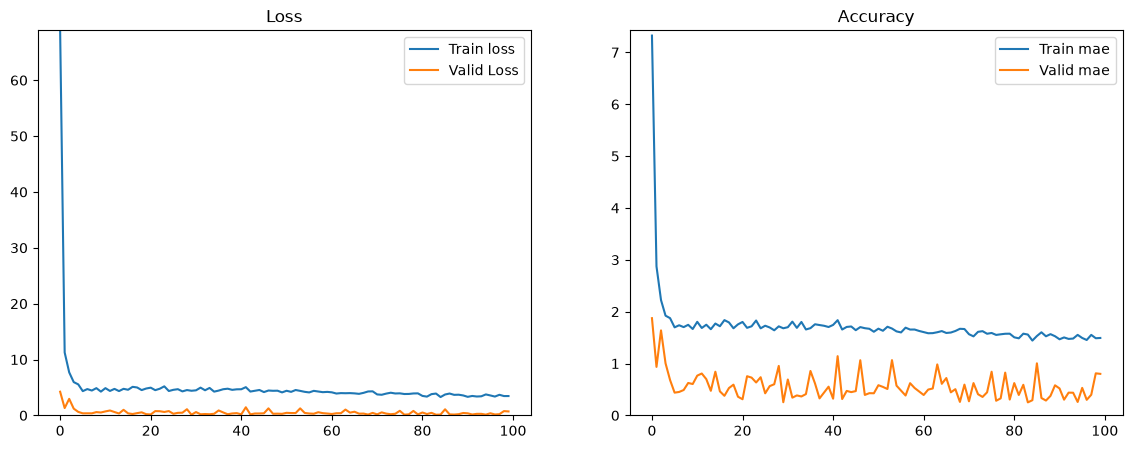

In [31]:
plot_loss_metrics(train_losses, valid_losses, train_metric, valid_metric)

6. Измени архитектуру модели и улучши результат: 
    * измени число нейронов
    * попробуй использовать сигмоидную функцию активации: `nn.Sigmoid`
    * измени число слоев
    * поэкспериментируй с активационными функциями и дропаутом

In [32]:
# см. выше

In [33]:
print('Train loss:', train_losses)
print('Valid loss:', valid_losses)

print('Train MAE:', train_metric)
print('Valid MAE:', valid_metric)

Train loss: [np.float64(68.82015756460336), np.float64(11.259981192075289), np.float64(7.702058278597319), np.float64(5.960063934326172), np.float64(5.550314683180589), np.float64(4.3421274698697605), np.float64(4.710217806009146), np.float64(4.450330330775334), np.float64(4.877183657426101), np.float64(4.255518032954289), np.float64(4.877774018507737), np.float64(4.375716356130747), np.float64(4.746776269032405), np.float64(4.349186897277832), np.float64(4.754719752531785), np.float64(4.587072482475867), np.float64(5.1109487276810865), np.float64(4.997279130495512), np.float64(4.529015559416551), np.float64(4.809881687164307), np.float64(4.9620223595545845), np.float64(4.515997079702524), np.float64(4.771855317629301), np.float64(5.200402718323928), np.float64(4.3635110304905815), np.float64(4.577619240834163), np.float64(4.689275026321411), np.float64(4.298070724193867), np.float64(4.533414877378023), np.float64(4.408198705086341), np.float64(4.486417366908147), np.float64(4.96894676

In [34]:
print('Минимальный Valid Loss:', min(valid_losses))
print('Минимальный Valid MAE:', min(valid_metric))

Минимальный Valid Loss: 0.12074852362275124
Минимальный Valid MAE: 0.25084844


In [35]:
print('Последний Train MAE:', train_metric[-1])
print('Последний Valid MAE:', valid_metric[-1])

Последний Train MAE: 1.4928937875307524
Последний Valid MAE: 0.80094975


7. Попробуй добиться лучшего результата, чем получалось на прошлой неделе во время выполнения проекта!

In [36]:
# model.eval()

# predictions = []
# actual_values = []

# with torch.inference_mode():
#     for samples, labels in valid_loader:
#         outputs = model(samples).squeeze(-1)

#         predictions.extend(outputs.numpy())
#         actual_values.extend(labels.numpy())

# predictions = np.expm1(predictions)
# actual_values = np.expm1(actual_values)

# mae = np.mean(np.abs(predictions - actual_values))

# print('Neural Network MAE:', mae)

In [37]:
model.eval()

predictions = []
actual_values = []

with torch.inference_mode():
    for samples, labels in valid_loader:
        outputs = model(samples).squeeze(-1)
        predictions.extend(outputs.numpy())
        actual_values.extend(labels.numpy())

predictions = np.expm1(predictions)
actual_values = np.expm1(actual_values)

mae = np.mean(np.abs(predictions - actual_values))

print('Neural Network MAE:', mae)

Neural Network MAE: 103482.92


In [38]:
model.eval()

predictions = []
actual_values = []

with torch.inference_mode():
    for samples, labels in valid_loader:
        outputs = model(samples).squeeze(-1)
        predictions.extend(outputs.numpy())
        actual_values.extend(labels.numpy())

predictions = np.expm1(predictions)
actual_values = np.expm1(actual_values)

mae = np.mean(np.abs(predictions - actual_values))

print('Neural Network MAE:', mae)

Neural Network MAE: 103482.914


In [39]:
print('Train loss:', train_losses)
print('Valid loss:', valid_losses)
print('Train MAE:', train_metric)
print('Valid MAE:', valid_metric)

Train loss: [np.float64(68.82015756460336), np.float64(11.259981192075289), np.float64(7.702058278597319), np.float64(5.960063934326172), np.float64(5.550314683180589), np.float64(4.3421274698697605), np.float64(4.710217806009146), np.float64(4.450330330775334), np.float64(4.877183657426101), np.float64(4.255518032954289), np.float64(4.877774018507737), np.float64(4.375716356130747), np.float64(4.746776269032405), np.float64(4.349186897277832), np.float64(4.754719752531785), np.float64(4.587072482475867), np.float64(5.1109487276810865), np.float64(4.997279130495512), np.float64(4.529015559416551), np.float64(4.809881687164307), np.float64(4.9620223595545845), np.float64(4.515997079702524), np.float64(4.771855317629301), np.float64(5.200402718323928), np.float64(4.3635110304905815), np.float64(4.577619240834163), np.float64(4.689275026321411), np.float64(4.298070724193867), np.float64(4.533414877378023), np.float64(4.408198705086341), np.float64(4.486417366908147), np.float64(4.96894676

In [40]:
print('Минимальный Valid MAE:', min(valid_metric))
print('Последний Valid MAE:', valid_metric[-1])

Минимальный Valid MAE: 0.25084844
Последний Valid MAE: 0.80094975


In [41]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(64, 1)
)

optimizer = optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.L1Loss()

In [42]:
train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 100)

Epoch 1 finished: train_loss=12.143, valid_loss=12.113
Epoch 2 finished: train_loss=12.050, valid_loss=12.019
Epoch 3 finished: train_loss=11.958, valid_loss=11.917
Epoch 4 finished: train_loss=11.846, valid_loss=11.785
Epoch 5 finished: train_loss=11.688, valid_loss=11.589
Epoch 6 finished: train_loss=11.469, valid_loss=11.334
Epoch 7 finished: train_loss=11.164, valid_loss=10.984
Epoch 8 finished: train_loss=10.763, valid_loss=10.516
Epoch 9 finished: train_loss=10.234, valid_loss=9.921
Epoch 10 finished: train_loss=9.577, valid_loss=9.178
Epoch 11 finished: train_loss=8.746, valid_loss=8.259
Epoch 12 finished: train_loss=7.741, valid_loss=7.141
Epoch 13 finished: train_loss=6.516, valid_loss=5.824
Epoch 14 finished: train_loss=5.074, valid_loss=4.225
Epoch 15 finished: train_loss=3.377, valid_loss=2.407
Epoch 16 finished: train_loss=1.502, valid_loss=0.672
Epoch 17 finished: train_loss=0.852, valid_loss=0.564
Epoch 18 finished: train_loss=0.703, valid_loss=0.334
Epoch 19 finished: t

In [43]:
model.eval()

predictions = []
actual_values = []

with torch.inference_mode():
    for samples, labels in valid_loader:
        outputs = model(samples).squeeze(-1)
        predictions.extend(outputs.numpy())
        actual_values.extend(labels.numpy())

predictions = np.expm1(predictions)
actual_values = np.expm1(actual_values)

mae = np.mean(np.abs(predictions - actual_values))

print('Neural Network MAE:', mae)

Neural Network MAE: 49837.395


In [44]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(64, 1)
)

optimizer = optim.Adam(model.parameters(), lr=0.0005)
criterion = nn.L1Loss()

train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 100)

Epoch 1 finished: train_loss=11.979, valid_loss=11.735
Epoch 2 finished: train_loss=11.308, valid_loss=10.641
Epoch 3 finished: train_loss=9.553, valid_loss=7.928
Epoch 4 finished: train_loss=5.598, valid_loss=2.232
Epoch 5 finished: train_loss=1.389, valid_loss=0.834
Epoch 6 finished: train_loss=0.846, valid_loss=0.404
Epoch 7 finished: train_loss=0.696, valid_loss=0.461
Epoch 8 finished: train_loss=0.639, valid_loss=0.241
Epoch 9 finished: train_loss=0.656, valid_loss=0.494
Epoch 10 finished: train_loss=0.652, valid_loss=0.229
Epoch 11 finished: train_loss=0.639, valid_loss=0.185
Epoch 12 finished: train_loss=0.653, valid_loss=0.181
Epoch 13 finished: train_loss=0.640, valid_loss=0.211
Epoch 14 finished: train_loss=0.638, valid_loss=0.308
Epoch 15 finished: train_loss=0.620, valid_loss=0.224
Epoch 16 finished: train_loss=0.612, valid_loss=0.188
Epoch 17 finished: train_loss=0.644, valid_loss=0.253
Epoch 18 finished: train_loss=0.603, valid_loss=0.199
Epoch 19 finished: train_loss=0.6

In [45]:
model.eval()

predictions = []
actual_values = []

with torch.inference_mode():
    for samples, labels in valid_loader:
        outputs = model(samples).squeeze(-1)
        predictions.extend(outputs.numpy())
        actual_values.extend(labels.numpy())

predictions = np.expm1(predictions)
actual_values = np.expm1(actual_values)

mae = np.mean(np.abs(predictions - actual_values))

print('Neural Network MAE:', mae)

Neural Network MAE: 39105.062


In [46]:
model = nn.Sequential(
    nn.Linear(n_features, 299),
    nn.ReLU(),
    nn.Linear(299, 128),
    nn.Sigmoid(),
    nn.Dropout(0.5),
    nn.Linear(128, 84),
    nn.Sigmoid(),
    nn.Dropout(0.5),
    nn.Linear(84, 64),
    nn.Sigmoid(),
    nn.Linear(64, 1)
)

optimizer = optim.SGD(model.parameters(), lr=0.001) 
criterion = nn.MSELoss()


train_losses, valid_losses, train_metric, valid_metric = fit_model(model, 100)

Epoch 1 finished: train_loss=94.352, valid_loss=52.106
Epoch 2 finished: train_loss=32.084, valid_loss=15.379
Epoch 3 finished: train_loss=8.864, valid_loss=3.743
Epoch 4 finished: train_loss=2.281, valid_loss=0.878
Epoch 5 finished: train_loss=0.589, valid_loss=0.295
Epoch 6 finished: train_loss=0.289, valid_loss=0.204
Epoch 7 finished: train_loss=0.234, valid_loss=0.163
Epoch 8 finished: train_loss=0.241, valid_loss=0.169
Epoch 9 finished: train_loss=0.229, valid_loss=0.166
Epoch 10 finished: train_loss=0.225, valid_loss=0.163
Epoch 11 finished: train_loss=0.215, valid_loss=0.162
Epoch 12 finished: train_loss=0.221, valid_loss=0.161
Epoch 13 finished: train_loss=0.217, valid_loss=0.162
Epoch 14 finished: train_loss=0.215, valid_loss=0.160
Epoch 15 finished: train_loss=0.229, valid_loss=0.162
Epoch 16 finished: train_loss=0.212, valid_loss=0.167
Epoch 17 finished: train_loss=0.210, valid_loss=0.162
Epoch 18 finished: train_loss=0.224, valid_loss=0.156
Epoch 19 finished: train_loss=0.2

In [47]:
model.eval()

predictions = []
actual_values = []

with torch.inference_mode():
    for samples, labels in valid_loader:
        outputs = model(samples).squeeze(-1)
        predictions.extend(outputs.numpy())
        actual_values.extend(labels.numpy())

predictions = np.expm1(predictions)
actual_values = np.expm1(actual_values)

mae = np.mean(np.abs(predictions - actual_values))

print('Neural Network MAE:', mae)

Neural Network MAE: 57283.91


## Дополнительное задание

### Классификация клиента банка 

* С помощью `pytorch` классифицировать клиентов банка. 

* Датасет [здесь](https://raw.githubusercontent.com/Anurion/Uralsib_test/main/Uralsib_test/Data.txt)

* Метрика: `f1_score`

* При чтении данных нужно указать аргумент `read_csv()` `encoding='kz1048'`